In [13]:
import numpy as np
import matplotlib.pyplot as plt
import importlib

import zernike
import phase_screen
import reconstruction
import psf_tools



importlib.reload(zernike)
importlib.reload(phase_screen)
importlib.reload(reconstruction)
importlib.reload(psf_tools)

from zernike import (
    make_pupil_grid,
    generate_zernike_modes,
    number_of_zernike_modes,
)

from phase_screen import fourier_phase_screen

from reconstruction import (
    build_response_matrix,
    measure_slopes,
    reconstruct_wavefront,
    residual_wavefront,
    rms,
)

from psf_tools import (
    compute_psf_from_phase,
    strehl_ratio,
    radial_profile,
)

In [2]:
N = 256
diameter = 1.0
n_lenslets = 20

X, Y, rho, theta, mask, dx = make_pupil_grid(
    N=N,
    diameter=diameter,
)

W_atm, _, _, _ = fourier_phase_screen(
    N=N,
    delta=dx,
    r0=0.20,
    L0=25.0,
    diameter=diameter,
    seed=4,
    target_rms_rad=1.0,
)

print(f"Atmospheric wavefront RMS: {rms(W_atm, mask):.4f} rad")

Atmospheric wavefront RMS: 0.9999 rad


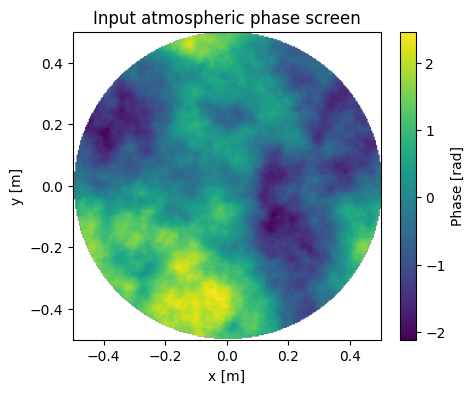

In [3]:
extent = [
    np.nanmin(X),
    np.nanmax(X),
    np.nanmin(Y),
    np.nanmax(Y),
]

plt.figure(figsize=(5, 4))
plt.imshow(
    W_atm,
    extent=extent,
    origin="lower",
)
plt.colorbar(label="Phase [rad]")
plt.title("Input atmospheric phase screen")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.show()

In [4]:
def run_modal_reconstruction_with_max_order(
    W_true,
    X,
    Y,
    rho,
    theta,
    mask,
    max_radial_order,
    n_lenslets=20,
    noise_std=0.0,
    seed=1,
    rcond=1e-4,
):
    """
    Reconstruct a wavefront using all Zernike modes up to max_radial_order.
    """
    modes = generate_zernike_modes(
        rho,
        theta,
        mask,
        max_radial_order=max_radial_order,
        include_piston=False,
        normalization=True,
    )

    centers, slopes = measure_slopes(
        W_true,
        mask,
        X,
        Y,
        n_lenslets=n_lenslets,
        min_fill=0.5,
        noise_std=noise_std,
        seed=seed,
    )

    A, names, _ = build_response_matrix(
        modes,
        mask,
        X,
        Y,
        n_lenslets=n_lenslets,
        min_fill=0.5,
    )

    coeffs, W_rec, residuals, rank, singular_values = reconstruct_wavefront(
        slopes,
        A,
        modes,
        names,
        mask,
        rcond=rcond,
    )

    res = residual_wavefront(W_true, W_rec, mask)

    condition_number = singular_values[0] / singular_values[-1]

    return {
        "modes": modes,
        "names": names,
        "coeffs": coeffs,
        "centers": centers,
        "slopes": slopes,
        "A": A,
        "W_rec": W_rec,
        "residual": res,
        "input_rms": rms(W_true, mask),
        "residual_rms": rms(res, mask),
        "rank": rank,
        "singular_values": singular_values,
        "condition_number": condition_number,
        "n_modes": len(names),
    }

In [5]:
max_orders = np.array([2, 3, 4, 5, 6, 7, 8, 9, 10])

results = []

for max_order in max_orders:
    result = run_modal_reconstruction_with_max_order(
        W_atm,
        X,
        Y,
        rho,
        theta,
        mask,
        max_radial_order=int(max_order),
        n_lenslets=n_lenslets,
        noise_std=0.0,
        seed=1,
        rcond=1e-4,
    )

    results.append(result)

    print(
        f"max_order = {max_order:2d}, "
        f"n_modes = {result['n_modes']:3d}, "
        f"rank = {result['rank']:3d}, "
        f"residual RMS = {result['residual_rms']:.4f} rad, "
        f"condition = {result['condition_number']:.2e}"
    )

max_order =  2, n_modes =   5, rank =   5, residual RMS = 0.7561 rad, condition = 1.33e+00
max_order =  3, n_modes =   9, rank =   9, residual RMS = 0.6325 rad, condition = 1.86e+00
max_order =  4, n_modes =  14, rank =  14, residual RMS = 0.5369 rad, condition = 2.39e+00
max_order =  5, n_modes =  20, rank =  20, residual RMS = 0.4647 rad, condition = 3.43e+00
max_order =  6, n_modes =  27, rank =  27, residual RMS = 0.4367 rad, condition = 4.23e+00
max_order =  7, n_modes =  35, rank =  35, residual RMS = 0.4085 rad, condition = 5.75e+00
max_order =  8, n_modes =  44, rank =  44, residual RMS = 0.3908 rad, condition = 6.68e+00
max_order =  9, n_modes =  54, rank =  54, residual RMS = 0.3734 rad, condition = 8.65e+00
max_order = 10, n_modes =  65, rank =  65, residual RMS = 0.3077 rad, condition = 9.55e+00


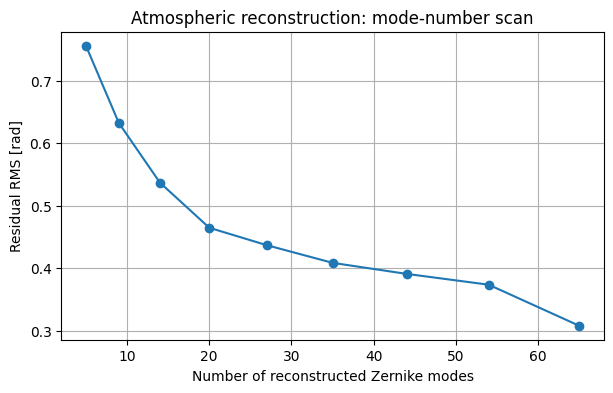

In [6]:
n_modes = np.array([r["n_modes"] for r in results])
residual_rms_values = np.array([r["residual_rms"] for r in results])
condition_values = np.array([r["condition_number"] for r in results])
rank_values = np.array([r["rank"] for r in results])

plt.figure(figsize=(7, 4))

plt.plot(
    n_modes,
    residual_rms_values,
    marker="o",
)

plt.xlabel("Number of reconstructed Zernike modes")
plt.ylabel("Residual RMS [rad]")
plt.title("Atmospheric reconstruction: mode-number scan")
plt.grid(True)
plt.show()

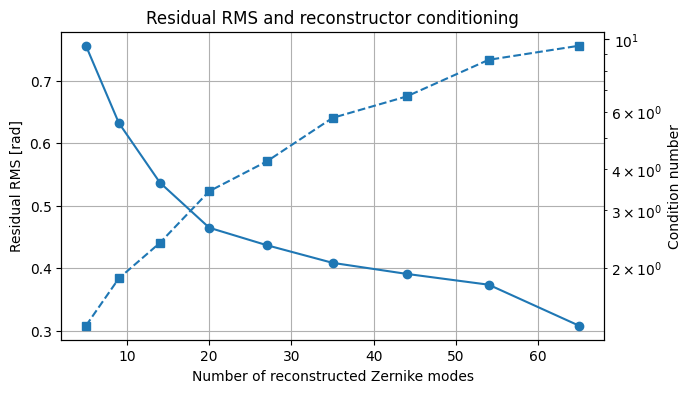

In [7]:
fig, ax1 = plt.subplots(figsize=(7, 4))

ax1.plot(
    n_modes,
    residual_rms_values,
    marker="o",
)
ax1.set_xlabel("Number of reconstructed Zernike modes")
ax1.set_ylabel("Residual RMS [rad]")
ax1.grid(True)

ax2 = ax1.twinx()
ax2.semilogy(
    n_modes,
    condition_values,
    marker="s",
    linestyle="--",
)
ax2.set_ylabel("Condition number")

plt.title("Residual RMS and reconstructor conditioning")
plt.show()

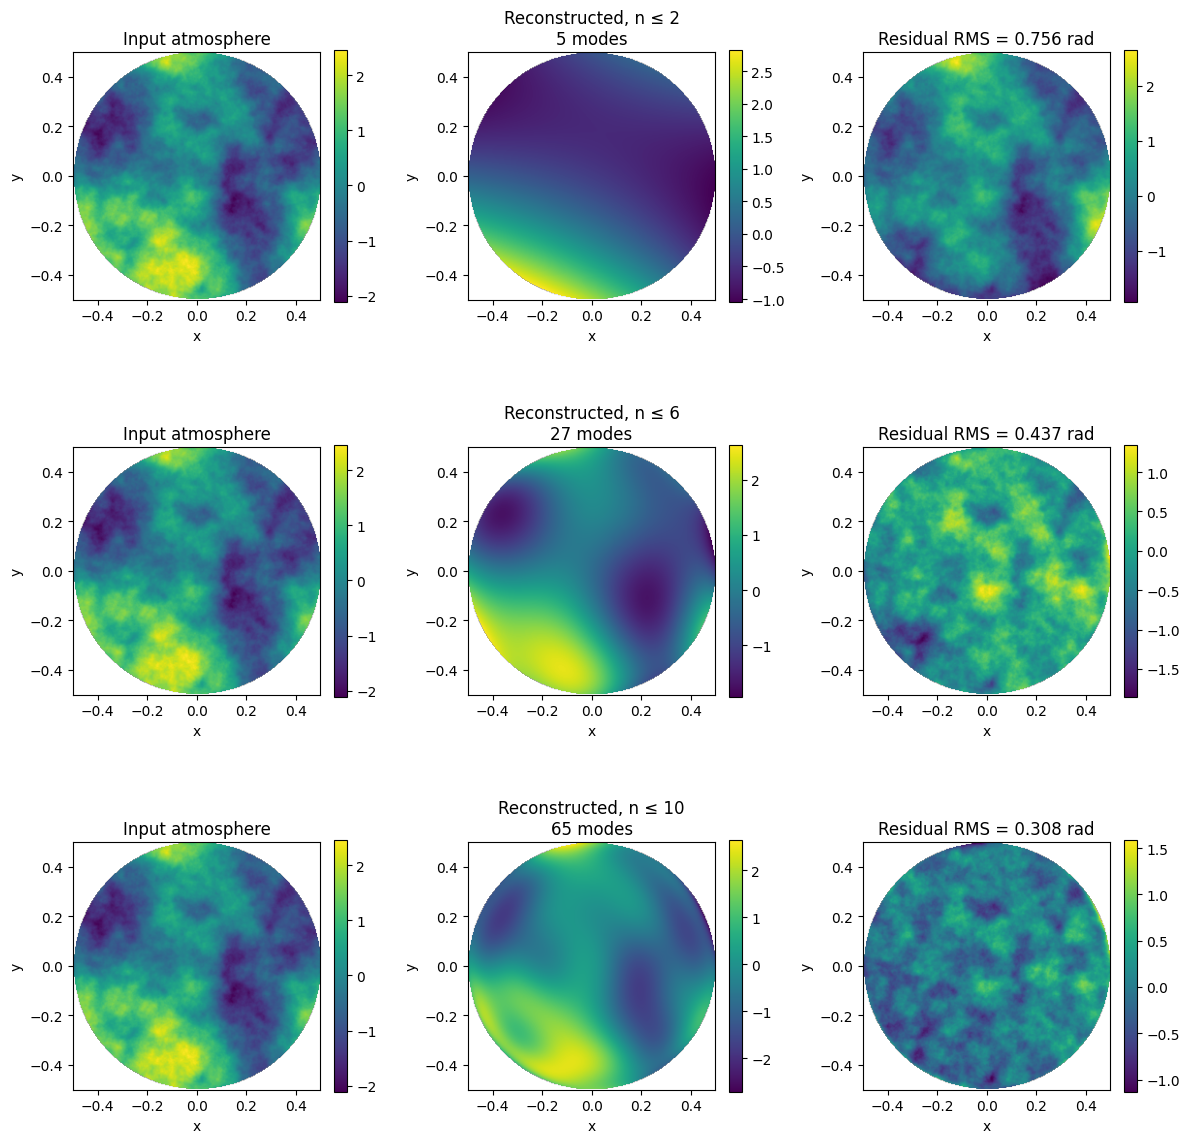

In [8]:
selected_indices = [0, len(results)//2, -1]

fig, axes = plt.subplots(len(selected_indices), 3, figsize=(12, 4 * len(selected_indices)))

for row, idx in enumerate(selected_indices):
    r = results[idx]

    max_order = max_orders[idx]
    W_rec = r["W_rec"]
    res = r["residual"]

    im0 = axes[row, 0].imshow(
        W_atm,
        extent=extent,
        origin="lower",
    )
    axes[row, 0].set_title("Input atmosphere")
    axes[row, 0].set_xlabel("x")
    axes[row, 0].set_ylabel("y")
    plt.colorbar(im0, ax=axes[row, 0], fraction=0.046)

    im1 = axes[row, 1].imshow(
        W_rec,
        extent=extent,
        origin="lower",
    )
    axes[row, 1].set_title(f"Reconstructed, n ≤ {max_order}\n{r['n_modes']} modes")
    axes[row, 1].set_xlabel("x")
    axes[row, 1].set_ylabel("y")
    plt.colorbar(im1, ax=axes[row, 1], fraction=0.046)

    im2 = axes[row, 2].imshow(
        res,
        extent=extent,
        origin="lower",
    )
    axes[row, 2].set_title(f"Residual RMS = {r['residual_rms']:.3f} rad")
    axes[row, 2].set_xlabel("x")
    axes[row, 2].set_ylabel("y")
    plt.colorbar(im2, ax=axes[row, 2], fraction=0.046)

plt.tight_layout()
plt.show()

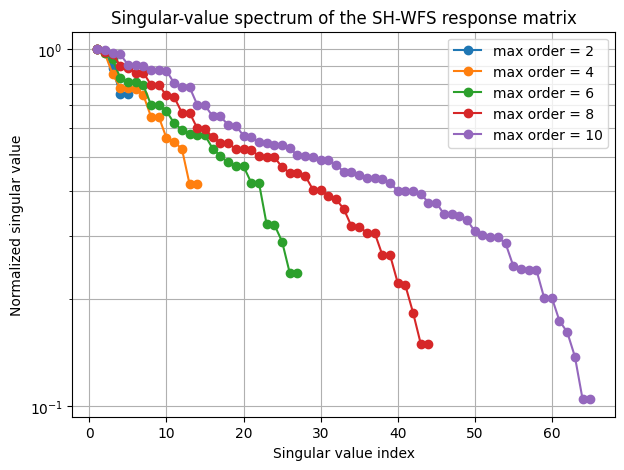

In [9]:
selected_orders = [2, 4, 6, 8, 10]

plt.figure(figsize=(7, 5))

for max_order in selected_orders:
    result = run_modal_reconstruction_with_max_order(
        W_atm,
        X,
        Y,
        rho,
        theta,
        mask,
        max_radial_order=max_order,
        n_lenslets=n_lenslets,
        noise_std=0.0,
        seed=1,
        rcond=1e-4,
    )

    svals = result["singular_values"]
    svals = svals / svals[0]

    plt.semilogy(
        np.arange(1, len(svals) + 1),
        svals,
        marker="o",
        label=f"max order = {max_order}"
    )

plt.xlabel("Singular value index")
plt.ylabel("Normalized singular value")
plt.title("Singular-value spectrum of the SH-WFS response matrix")
plt.grid(True, which="both")
plt.legend()
plt.show()

The condition number quantifies the numerical stability of the wavefront reconstruction problem. It is defined as the ratio between the largest and smallest singular values of the Shack-Hartmann response matrix. A low condition number means that all reconstructed modes are sensed with comparable sensitivity. A high condition number means that some modal combinations produce weak or nearly degenerate slope signals, so the inverse reconstruction can amplify noise.

As the maximum Zernike radial order increases, more high-spatial-frequency modes are included. These modes are harder to sample with a finite lenslet array and may produce similar averaged slope patterns. Therefore, the smallest singular values decrease and the condition number increases. This reflects the trade-off between fitting more atmospheric turbulence modes and maintaining a stable wavefront reconstruction.

In [14]:
strehl_values = []

for result in results:
    W_res = result["residual"]
    S = strehl_ratio(W_res, mask, pad_factor=4)
    strehl_values.append(S)

strehl_values = np.array(strehl_values)

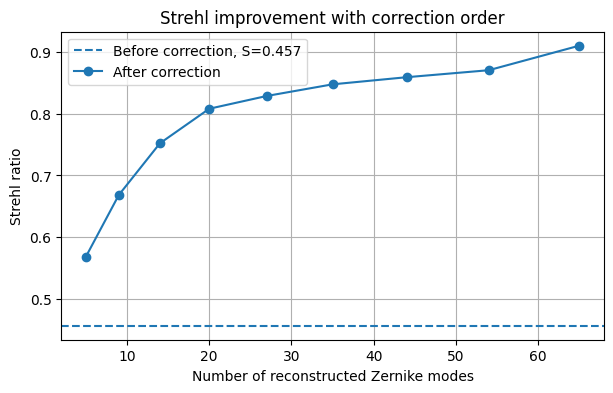

In [16]:
strehl_before = strehl_ratio(W_atm, mask, pad_factor=4)

plt.figure(figsize=(7, 4))

plt.axhline(
    strehl_before,
    linestyle="--",
    label=f"Before correction, S={strehl_before:.3f}",
)

plt.plot(
    n_modes,
    strehl_values,
    marker="o",
    label="After correction",
)

plt.xlabel("Number of reconstructed Zernike modes")
plt.ylabel("Strehl ratio")
plt.title("Strehl improvement with correction order")
plt.grid(True)
plt.legend()
plt.show()